# Q2 - Data quality and outliers

Can we trust the data? Which strange values should we deal with before modelling?

We look at: missing values, duplicates, lobby consistency, distributions (violin plots) and kills vs deaths.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / 'src'))  # not needed after `pip install -e .`

from ubi_churn.config import DataCatalog, load_params

catalog = DataCatalog.from_config()  # conf/base/catalog.yml
params = load_params()  # conf/base/parameters.yml

import matplotlib.pyplot as plt
import missingno as msno
import numpy as np
import pandas as pd
import polars as pl
import seaborn as sns
from matplotlib.colors import LogNorm

from ubi_churn.utils import exploration as ex

ex.set_plot_style()
NUM_COLUMNS: list[str] = params['preprocessing']['integer_columns']

df_player_matches: pl.DataFrame = catalog.load('player_matches')
row_count: int = df_player_matches.height
print(df_player_matches.shape)

(95733, 11)


## 1. Missing values

shape: (11, 3)
┌───────────────────┬────────────┬──────────┐
│ column            ┆ null_count ┆ null_pct │
│ ---               ┆ ---        ┆ ---      │
│ str               ┆ u32        ┆ f64      │
╞═══════════════════╪════════════╪══════════╡
│ kills             ┆ 153        ┆ 0.16     │
│ death             ┆ 153        ┆ 0.16     │
│ opponentid        ┆ 11         ┆ 0.011    │
│ teammateid        ┆ 6          ┆ 0.006    │
│ playerid          ┆ 0          ┆ 0.0      │
│ …                 ┆ …          ┆ …        │
│ gamemode          ┆ 0          ┆ 0.0      │
│ victory           ┆ 0          ┆ 0.0      │
│ match_datetime    ┆ 0          ┆ 0.0      │
│ playernb_in_match ┆ 0          ┆ 0.0      │
│ still_active      ┆ 0          ┆ 0.0      │
└───────────────────┴────────────┴──────────┘


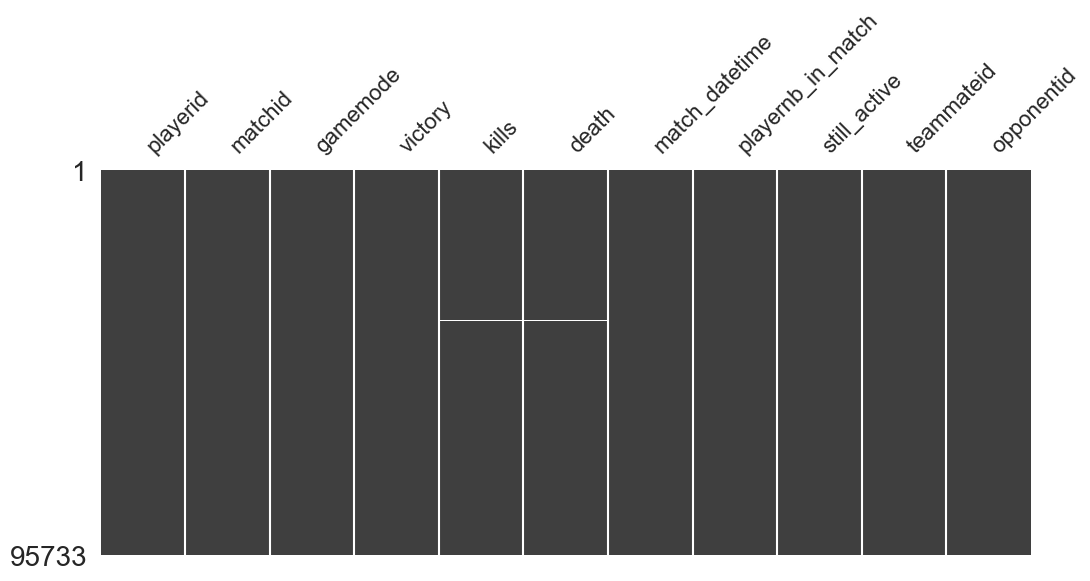

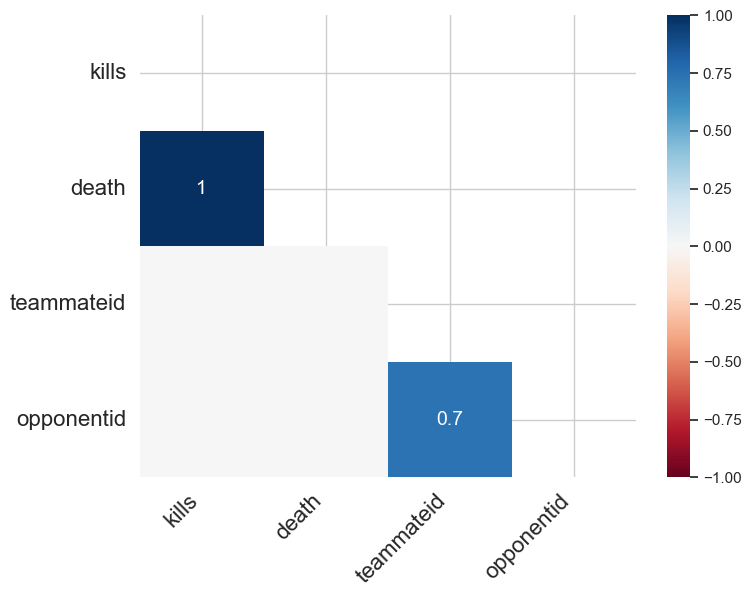

In [2]:
print(ex.null_summary(df_player_matches))

# missingno works on pandas
msno.matrix(df_player_matches.to_pandas(), figsize=(12, 5), sparkline=False)
plt.show()
msno.heatmap(df_player_matches.to_pandas(), figsize=(8, 6))
plt.show()

Observation :
- Only a few columns have nulls: kills and death (153 rows, always missing together), teammateid (6) and opponentid (11).
- More than 99.8% of the data is complete, so nulls are not a problem.
- Next, we check if the missing kills / death are random or linked to a mode, a result or a date.

In [3]:
df_null_performance: pl.DataFrame = df_player_matches.filter(pl.col('kills').is_null())
print(df_null_performance.group_by('gamemode', 'victory').len().sort('gamemode', 'victory'))
print(df_null_performance['match_datetime'].dt.date().value_counts().sort('match_datetime'))
print('distinct players concerned:', df_null_performance['playerid'].n_unique())

shape: (6, 3)
┌──────────────┬─────────┬─────┐
│ gamemode     ┆ victory ┆ len │
│ ---          ┆ ---     ┆ --- │
│ str          ┆ str     ┆ u32 │
╞══════════════╪═════════╪═════╡
│ PVP          ┆ FALSE   ┆ 24  │
│ PVP          ┆ TRUE    ┆ 22  │
│ PVP_RANKED   ┆ FALSE   ┆ 38  │
│ PVP_RANKED   ┆ TRUE    ┆ 42  │
│ PVP_UNRANKED ┆ FALSE   ┆ 13  │
│ PVP_UNRANKED ┆ TRUE    ┆ 14  │
└──────────────┴─────────┴─────┘
shape: (2, 2)
┌────────────────┬───────┐
│ match_datetime ┆ count │
│ ---            ┆ ---   │
│ date           ┆ u32   │
╞════════════════╪═══════╡
│ 2025-10-10     ┆ 1     │
│ 2025-12-09     ┆ 152   │
└────────────────┴───────┘
distinct players concerned: 43


## 2. Duplicates and consistency

In [4]:
print('duplicated (player, match):', row_count - df_player_matches.select('playerid', 'matchid').unique().height)
print('matchid appearing more than once (rows):', row_count - df_player_matches['matchid'].n_unique())
print('fully duplicated rows:', row_count - df_player_matches.unique().height)

# a match with 2 rows should have 2 different players in the same lobby
df_player_matches.filter(pl.col('matchid').is_duplicated()).sort('matchid').select(
    'matchid', 'playerid', 'gamemode', 'victory', 'kills', 'death', 'playernb_in_match'
)

duplicated (player, match): 0
matchid appearing more than once (rows): 11
fully duplicated rows: 0


matchid,playerid,gamemode,victory,kills,death,playernb_in_match
str,str,str,str,i64,i64,i64
"""03080a9e-d0a0-4338-bff7-c63a5a…","""88cba154-adfc-4d84-8a69-186f73…","""PVP""","""FALSE""",4,3,10
"""03080a9e-d0a0-4338-bff7-c63a5a…","""4e5dc5a9-f7a0-41fd-8918-e2300f…","""PVP""","""TRUE""",3,3,10
"""1767c1fb-8d41-489f-b381-d17bb8…","""a4b3846c-4ad7-485e-9f44-6b48b9…","""PVP_RANKED""","""FALSE""",5,6,10
"""1767c1fb-8d41-489f-b381-d17bb8…","""6f8e17d9-98d0-4c9d-aaa2-8bdd60…","""PVP_RANKED""","""TRUE""",5,7,10
"""3339abe7-ea37-4386-ae67-bbec9e…","""04964954-a0f6-4749-aefc-f76c4d…","""PVP""","""FALSE""",0,0,13
…,…,…,…,…,…,…
"""fcf4793c-53c4-457a-bb88-fbdfc6…","""8586b23e-95da-4486-a91b-8f4000…","""PVP""","""FALSE""",4,4,14
"""fdb6d7b6-b8b9-46e9-9846-42732d…","""8dbab1dd-3c40-4b6f-a6f1-e62a88…","""PVP_RANKED""","""FALSE""",5,5,10
"""fdb6d7b6-b8b9-46e9-9846-42732d…","""6f8e17d9-98d0-4c9d-aaa2-8bdd60…","""PVP_RANKED""","""TRUE""",10,3,10


Observation :
- The missing kills / death are spread over all modes and results, but 152 of the 153 are on the same day (2025-12-09), for 43 players. It looks like a logging incident, not random missing values.
- There is no duplicated (player, match) pair.
- 11 matches appear twice: two of our players were in the same match. We only have 840 players, not the full lobby.
- So one row = one player in one match, and `playernb_in_match` is the size of the lobby, not the number of rows we have.

In [5]:
# Logical consistency checks
print('zero kills AND zero deaths  :', df_player_matches.filter((pl.col('kills') == 0) & (pl.col('death') == 0)).height)
print('OPERATIONS rows             :', df_player_matches.filter(pl.col('gamemode') == 'OPERATIONS').height)
print('lobby size != 10            :', df_player_matches.filter(pl.col('playernb_in_match') != 10).height)
print('lobby size < 4 (solo)       :', df_player_matches.filter(pl.col('playernb_in_match') < 4).height)
print('draw / other                :', df_player_matches.filter(pl.col('victory').is_in(['draw', 'other'])).height)
print('max death                   :', df_player_matches['death'].max())
print(df_player_matches['death'].value_counts().sort('death'))

zero kills AND zero deaths  : 2134
OPERATIONS rows             : 5
lobby size != 10            : 25605
lobby size < 4 (solo)       : 6
draw / other                : 56
max death                   : 9
shape: (11, 2)
┌───────┬───────┐
│ death ┆ count │
│ ---   ┆ ---   │
│ i64   ┆ u32   │
╞═══════╪═══════╡
│ null  ┆ 153   │
│ 0     ┆ 4082  │
│ 1     ┆ 9041  │
│ 2     ┆ 12678 │
│ 3     ┆ 19145 │
│ …     ┆ …     │
│ 5     ┆ 14544 │
│ 6     ┆ 7224  │
│ 7     ┆ 3732  │
│ 8     ┆ 1714  │
│ 9     ┆ 292   │
└───────┴───────┘


Observation :
- Deaths stop at 9, nothing at 10: it looks like a cap from the game rules (to confirm with the game team).
- 2,134 rows have 0 kills and 0 deaths: probably players who were AFK, disconnected or left early. We should flag them.
- The lobby is not always 10 players: 25.6k rows are different. Ranked and unranked are almost always 10, but PVP is different 68% of the time (up to 25 players).

## 3. Players per game: does `playernb_in_match` match the teammate / opponent lists?

teammateid and opponentid are lists of player ids separated by commas. If the lobby size is right, we expect: teammates + opponents + 1 (the player himself) = `playernb_in_match`.

We also check if a player appears in his own teammate list.

In [6]:
df_lobby: pl.DataFrame = ex.add_lobby_columns(df_player_matches)

print('playerid found in its own teammateid :', df_lobby['self_in_teammate'].sum(), 'rows')
print('playerid found in its own opponentid :', df_lobby['self_in_opponent'].sum(), 'rows')
print()
print('gap if player is NOT counted (n_listed - playernb_in_match):')
print(df_lobby['gap_without_self'].value_counts().sort('gap_without_self'))
print('gap if player IS counted (n_listed + 1 - playernb_in_match):')
print(df_lobby['gap_with_self'].value_counts().sort('gap_with_self'))

playerid found in its own teammateid : 0 rows
playerid found in its own opponentid : 0 rows

gap if player is NOT counted (n_listed - playernb_in_match):
shape: (1, 2)
┌──────────────────┬───────┐
│ gap_without_self ┆ count │
│ ---              ┆ ---   │
│ i64              ┆ u32   │
╞══════════════════╪═══════╡
│ -1               ┆ 95733 │
└──────────────────┴───────┘
gap if player IS counted (n_listed + 1 - playernb_in_match):
shape: (1, 2)
┌───────────────┬───────┐
│ gap_with_self ┆ count │
│ ---           ┆ ---   │
│ i64           ┆ u32   │
╞═══════════════╪═══════╡
│ 0             ┆ 95733 │
└───────────────┴───────┘


Observation :
- A player is never in his own teammate (or opponent) list: the lists only hold the other players.
- teammates + opponents + 1 = `playernb_in_match` on 100% of the rows. So the lobby size is reliable: lobbies that are not 10 really are smaller or bigger.
- Next: are the two teams balanced?

In [7]:
print(ex.team_balance_by_mode(df_lobby))

df_lobby.filter(pl.col('team_size_gap') != 0).group_by('gamemode', 'team_size_gap').len().sort('gamemode', 'team_size_gap')

shape: (4, 7)
┌──────────────┬───────┬────────────────┬────────────────┬────────────────────┬─────────┬─────────┐
│ gamemode     ┆ rows  ┆ share_balanced ┆ team_size_mode ┆ opponent_size_mode ┆ gap_min ┆ gap_max │
│ ---          ┆ ---   ┆ ---            ┆ ---            ┆ ---                ┆ ---     ┆ ---     │
│ str          ┆ u32   ┆ f64            ┆ i64            ┆ i64                ┆ i64     ┆ i64     │
╞══════════════╪═══════╪════════════════╪════════════════╪════════════════════╪═════════╪═════════╡
│ PVP_RANKED   ┆ 48563 ┆ 0.95           ┆ 5              ┆ 5                  ┆ -3      ┆ 5       │
│ PVP          ┆ 32267 ┆ 0.384          ┆ 5              ┆ 5                  ┆ -11     ┆ 14      │
│ PVP_UNRANKED ┆ 14898 ┆ 0.934          ┆ 5              ┆ 5                  ┆ -2      ┆ 3       │
│ OPERATIONS   ┆ 5     ┆ 0.0            ┆ 1              ┆ 0                  ┆ 1       ┆ 1       │
└──────────────┴───────┴────────────────┴────────────────┴────────────────────┴───────

gamemode,team_size_gap,len
str,i64,u32
"""OPERATIONS""",1,5
"""PVP""",-11,1
"""PVP""",-10,3
"""PVP""",-9,6
"""PVP""",-8,10
…,…,…
"""PVP_UNRANKED""",-2,14
"""PVP_UNRANKED""",-1,389
"""PVP_UNRANKED""",1,558


Observation :
- The usual match is 5 vs 5.
- Ranked (95%) and unranked (93%) are almost always 5 vs 5; the rest is mostly one player more or less (someone left or joined late).
- PVP is balanced only 38% of the time, with gaps from -11 to +14: it is not a fixed 5v5 mode (custom or open lobbies), so we should analyse it separately.
- OPERATIONS has 5 rows with 1 player and no opponent (probably PvE).

## 4. Violin plot of numerical columns

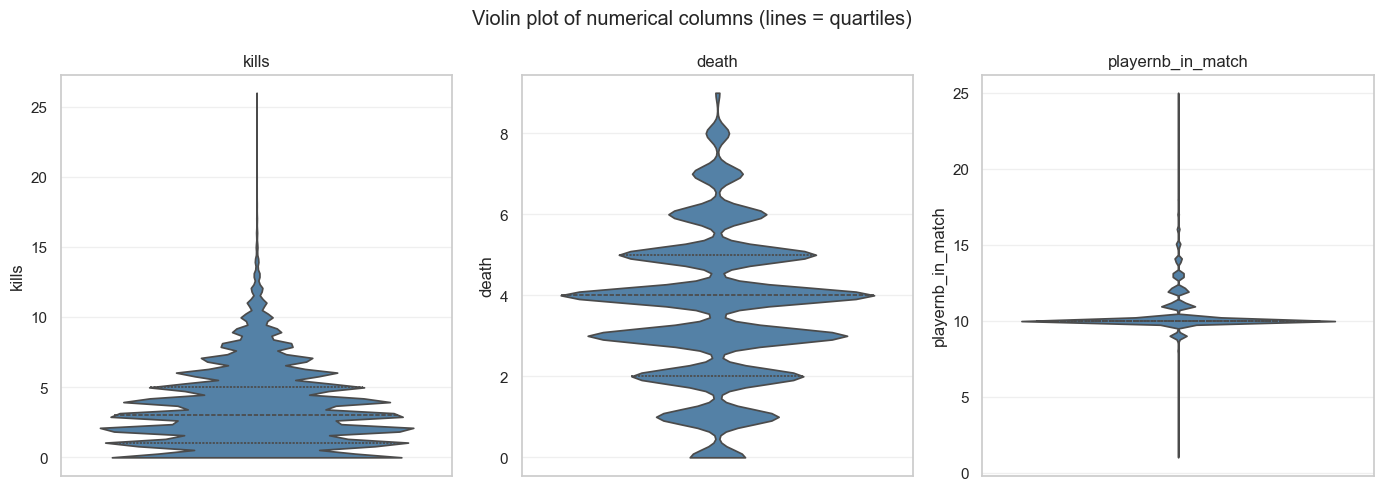

column,low,high,n_outliers,outlier_pct
str,f64,f64,i64,f64
"""kills""",-5.0,11.0,1106,1.16
"""death""",-2.5,9.5,0,0.0
"""playernb_in_match""",10.0,10.0,25605,26.75


In [8]:
df_pandas = df_player_matches.to_pandas()

fig, axes = plt.subplots(1, len(NUM_COLUMNS), figsize=(14, 5))
for ax, column_name in zip(axes, NUM_COLUMNS):
    sns.violinplot(data=df_pandas, y=column_name, inner='quartile', cut=0, color='steelblue', ax=ax)
    ax.set_title(column_name)
    ax.grid(axis='y', alpha=0.3)
fig.suptitle('Violin plot of numerical columns (lines = quartiles)')
fig.tight_layout()
plt.show()

ex.iqr_outliers(df_player_matches, NUM_COLUMNS)

Observation :
- Kills have a long tail up to 26 (above 12 is the top 1%). The 160 rows with 15+ kills are mostly wins in normal 10-player lobbies: they look like real good games, not errors.
- Deaths stay between 0 and 9, almost no outlier.
- Lobby size is almost always 10, so everything else looks like an outlier. It is not noise, it is a different type of match.

## 5. Violin plot per category

Each game mode shows two sides: victory TRUE / FALSE, then still_active TRUE / FALSE.

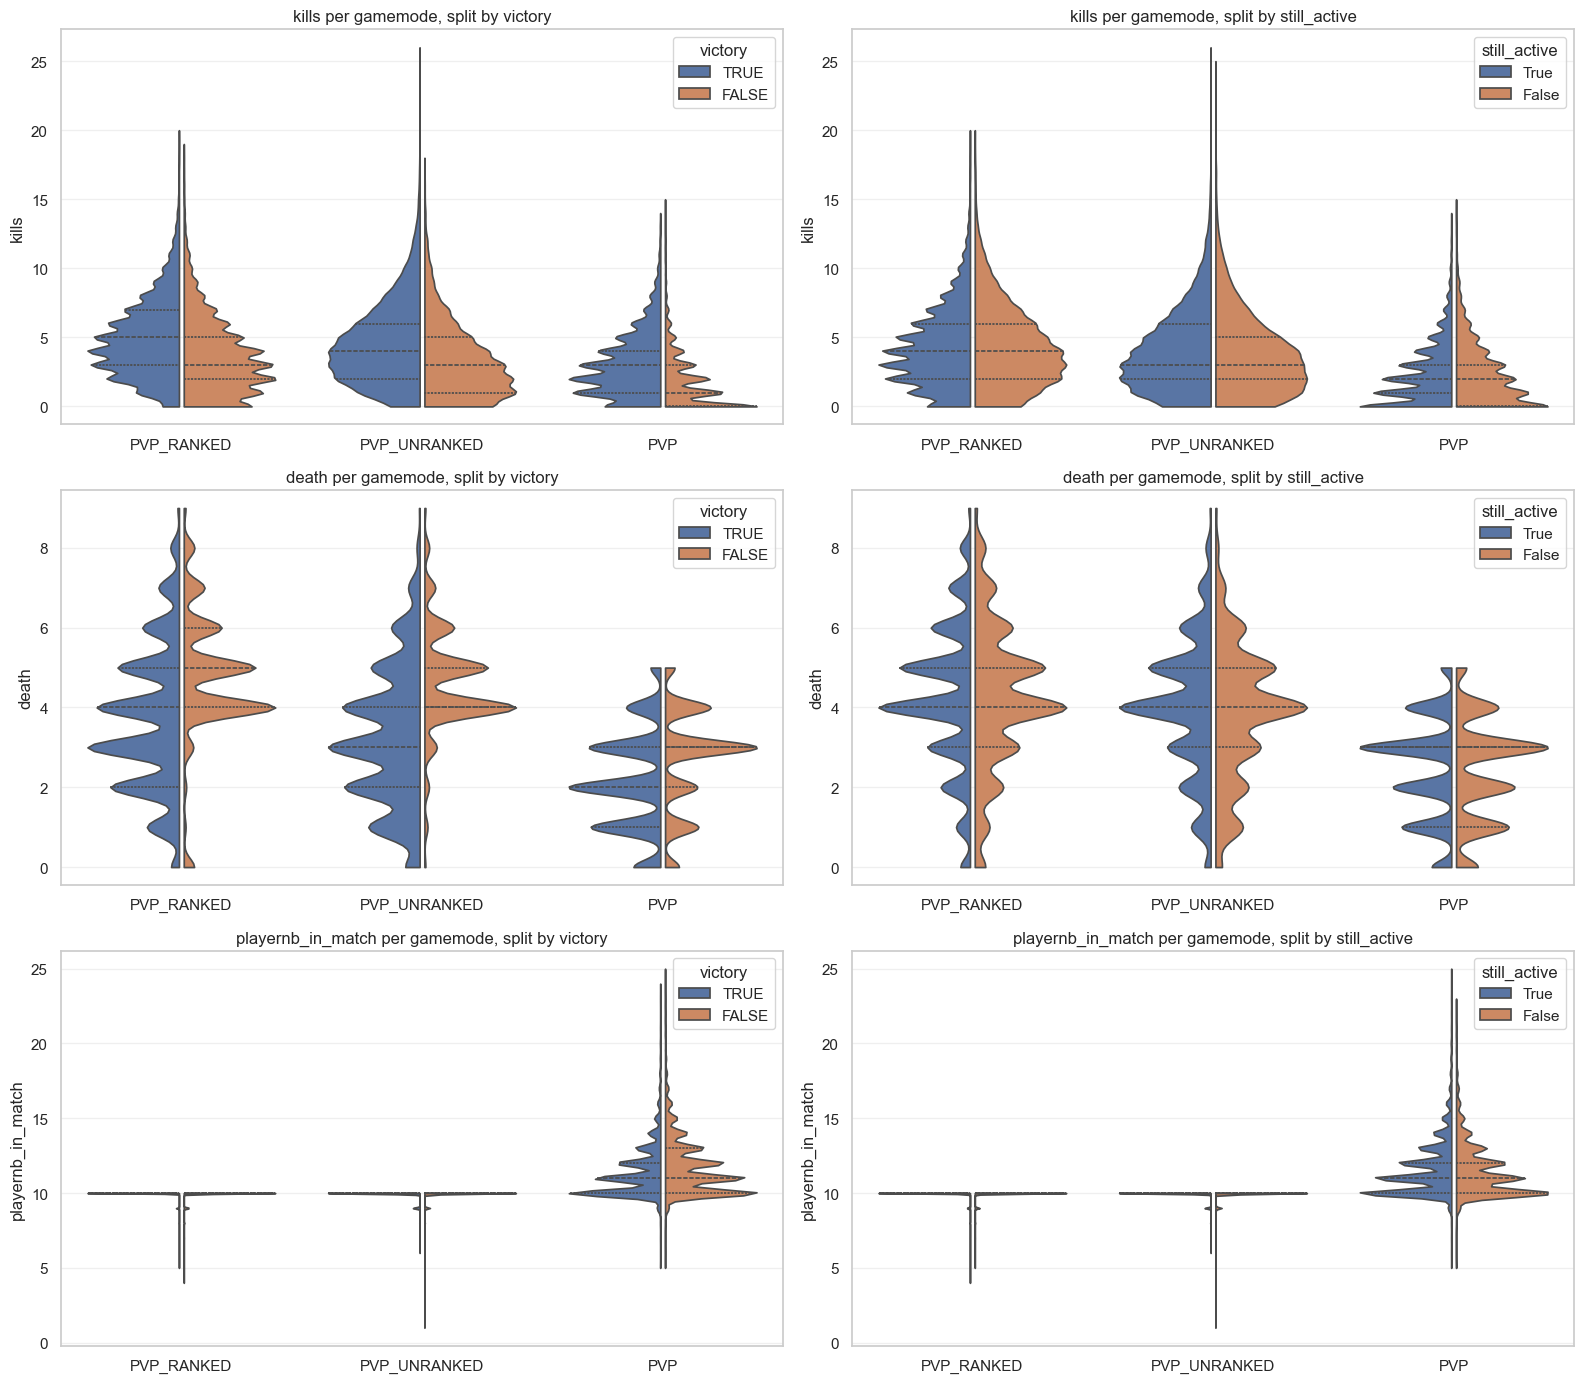

victory       FALSE   TRUE
gamemode                  
PVP           18283  13970
PVP_RANKED    24196  24336
PVP_UNRANKED   7279   7610


In [9]:
HUE_COLUMNS: list[str] = ['victory', 'still_active']
GAMEMODE_ORDER: list[str] = params['exploration']['gamemode_order']

# split violins need exactly 2 levels per hue: drop draw / other / OPERATIONS (61 rows)
df_split: pd.DataFrame = (
    df_player_matches
    .filter(pl.col('victory').is_in(['TRUE', 'FALSE']), pl.col('gamemode').is_in(GAMEMODE_ORDER))
    .with_columns(pl.col('still_active').cast(pl.String).str.to_titlecase())
    .to_pandas()
)

fig, axes = plt.subplots(len(NUM_COLUMNS), len(HUE_COLUMNS), figsize=(16, 14))
for row_index, num_column in enumerate(NUM_COLUMNS):
    for col_index, hue_column in enumerate(HUE_COLUMNS):
        ax = axes[row_index][col_index]
        ex.split_violin(
            ax, df_split, y=num_column, x='gamemode', hue=hue_column,
            order=GAMEMODE_ORDER, hue_order=sorted(df_split[hue_column].unique(), reverse=True),
        )
        ax.set_title(f'{num_column} per gamemode, split by {hue_column}')
        ax.set_xlabel('')
        ax.grid(axis='y', alpha=0.3)
fig.tight_layout()
plt.show()

print(df_split.groupby(['gamemode', 'victory']).size().unstack())

In [10]:
df_player_matches.group_by('gamemode').agg(
    pl.len().alias('rows'),
    pl.col('kills').mean().round(2).alias('kills_mean'),
    pl.col('death').mean().round(2).alias('death_mean'),
    pl.col('playernb_in_match').median().alias('lobby_median'),
    pl.col('playernb_in_match').max().alias('lobby_max'),
    (pl.col('playernb_in_match') != 10).mean().round(3).alias('share_lobby_not_10'),
).sort('rows', descending=True)

gamemode,rows,kills_mean,death_mean,lobby_median,lobby_max,share_lobby_not_10
str,u32,f64,f64,f64,i64,f64
"""PVP_RANKED""",48563,4.25,4.24,10.0,10,0.052
"""PVP""",32267,2.27,2.44,11.0,25,0.685
"""PVP_UNRANKED""",14898,3.92,3.94,10.0,10,0.067
"""OPERATIONS""",5,4.8,0.8,1.0,1,1.0


Observation :
- PVP has lobbies up to 25 and about half the kills / deaths of ranked (2.3 vs 4.2): it is a different population.
- OPERATIONS has only 5 rows: too small, we can drop it.
- Winners have 4.3 kills / 3.2 deaths vs 2.9 / 4.0 for losers, as expected. draw / other are only 56 rows.
- Inactive players have almost the same kills as active ones (3.4 vs 3.6): performance alone will probably not explain churn.

## 6. Scatterplot kills / death

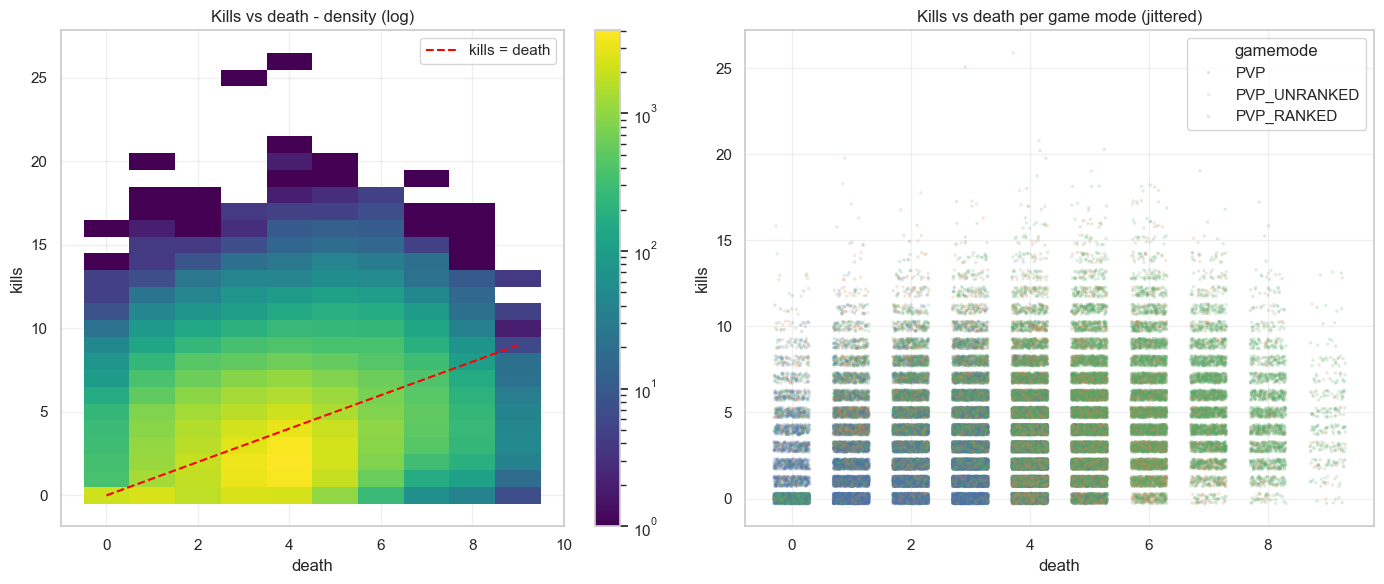

correlation kills/death: 0.24
rows with kills >= 15  : 160
rows with death == 0   : 4082


In [11]:
df_scatter = df_player_matches.drop_nulls(['kills', 'death']).to_pandas()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# left: values are integers, so points overlap: 2D histogram shows the density
sns.histplot(data=df_scatter, x='death', y='kills', discrete=(True, True), cmap='viridis', cbar=True, norm=LogNorm(), vmin=None, vmax=None, ax=axes[0])
axes[0].plot([0, 9], [0, 9], color='red', linestyle='--', label='kills = death')
axes[0].set_title('Kills vs death - density (log)')
axes[0].legend()

# right: per game mode, jittered
rng = np.random.default_rng(0)
df_jitter = df_scatter[df_scatter['gamemode'] != 'OPERATIONS'].copy()
df_jitter['death_jitter'] = df_jitter['death'] + rng.uniform(-0.3, 0.3, len(df_jitter))
df_jitter['kills_jitter'] = df_jitter['kills'] + rng.uniform(-0.3, 0.3, len(df_jitter))
sns.scatterplot(data=df_jitter, x='death_jitter', y='kills_jitter', hue='gamemode', s=6, alpha=0.2, linewidth=0, ax=axes[1])
axes[1].set_title('Kills vs death per game mode (jittered)')
axes[1].set_xlabel('death')
axes[1].set_ylabel('kills')

for ax in axes:
    ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

print('correlation kills/death:', round(df_scatter['kills'].corr(df_scatter['death']), 3))
print('rows with kills >= 15  :', (df_scatter['kills'] >= 15).sum())
print('rows with death == 0   :', (df_scatter['death'] == 0).sum())

Observation :
- Deaths hit a hard wall at 9 while kills go up to 26.
- Most games are between 0-8 kills and 1-6 deaths. Games with 15+ kills are the real outliers, but plausible.
- Kills and deaths are weakly correlated (0.24).
- Many rows at (0, 0): the AFK / left-early group.
- 4,082 rows have 0 deaths, so a per-match K/D would divide by zero: we compute K/D on totals.

## Conclusion

The data is clean overall:
- Very few missing values (0.16%), almost all from one incident day (2025-12-09).
- No duplicates: one row = one player in one match.
- Some odd values: draw / other in victory, OPERATIONS (5 rows), deaths capped at 9, 2,134 rows with 0 kills and 0 deaths.
- Lobby size goes from 1 to 25, but it is consistent with the teammate / opponent lists. Non-10 lobbies are mostly PVP, a different kind of match.
- 840 players, median 28 matches, max 1,974: a few heavy players weigh a lot.

What to do next:
1. Keep PVP_RANKED and PVP_UNRANKED for performance analysis, look at PVP separately, drop OPERATIONS and draw / other.
2. Leave the 2025-12-09 rows out of performance metrics (they are still fine for activity).
3. Flag (do not delete) the AFK-like rows and the very high kills.
4. Ask the business: what is PVP, why deaths stop at 9, and how `still_active` is computed.
5. Build a player-level table (one row per player), because `still_active` is a player label repeated on every row.